# Конечный заход: какая модель уточняет прогноз?
## Париж, Шарль-де-Голль, LFPG, 09L

**Исследование 05, 15 января 2025, Approach Risk 1.1**

**37 кандидатов, 35 бортов, 633 пары наблюдений, горизонт 30 ± 3 с**

Продолжение текущей Vz уже дает физический ориентир, а Ridge снижает ошибку. Следующий вопрос: помогают ли робастная линейная модель, нелинейное ядро или ансамбль деревьев на той же группе?

Сначала фиксируем пространство моделей и выбор по validation. Затем сравниваем прогнозы и исследуем, как модели реагируют на изменение текущей вертикальной скорости. Высотная точность и обнаружение нестабильного захода остаются разными задачами.

**Статус:** исследовательское расширение. Результаты этих test-заходов уже известны из этапа 04. Повторная проверка на них не является новым независимым подтверждением. Подтверждение переносимости требует другого дня.

**Маршрут:** baseline → общий протокол → обучение → выбор на validation → реакция на Vz → сравнение на test → разбор заходов → вывод.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn
from sklearn.model_selection import ParameterGrid
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from IPython.display import display
from IPython.display import HTML

BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
PROJECT = BASE.parents[1]
sys.path.insert(0, str(PROJECT / 'scripts'))
from lfpg_training import event_errors, summarize
from lfpg_model_comparison import (make_model, fit_model, forecast, paired_intervals,
                                   current_rate_response)
REPORTS, FIGURES = BASE / 'reports', BASE / 'figures'
ARTIFACTS = BASE / 'artifacts/training_05'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
plan_path = PROJECT / 'configs/lfpg_09l_model_comparison.json'
plan = json.loads(plan_path.read_text(encoding='utf-8'))
prior = json.loads((REPORTS / '04_training_manifest.json').read_text(encoding='utf-8'))
inherited = json.loads((PROJECT / plan['inherited_protocol']).read_text(encoding='utf-8'))

def digest(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

examples_path = BASE / plan['examples']
cohort_path = BASE / plan['split']
assert digest(examples_path) == prior['examples_sha256']
for relative, expected in prior['inputs_sha256'].items():
    assert digest(BASE / relative) == expected
examples = pd.read_parquet(examples_path)
cohort = pd.read_csv(cohort_path)
FEATURES = plan['features']
assert FEATURES == inherited['features']
assert len(examples) == 633 and len(cohort) == 37 and cohort.icao24.nunique() == 35
for key in ['icao24', 'trace_id', 'event_id']:
    assert examples.groupby(key).split.nunique().eq(1).all()
assert examples.origin_metar_available_time.le(examples.origin_time).all()
assert examples.target_time.gt(examples.origin_time).all()
assert examples.horizon_s.between(27, 33).all()
assert np.allclose(examples.baseline_ft,
                   examples.height_ft + examples.vertical_rate_fps * examples.horizon_s)
assert not set(FEATURES) & {'target_height_ft', 'residual_ft', 'target_time', 'event_id', 'icao24', 'boundary_time'}
train = examples.loc[examples.split.eq('train')].copy()
validation = examples.loc[examples.split.eq('validation')].copy()
weights = 1 / train.groupby('event_id').event_id.transform('size')
weights *= len(train) / weights.sum()
assert np.allclose(weights.groupby(train.event_id).sum(), len(train) / train.event_id.nunique())

# Общая палитра продолжает оформление предыдущего эксперимента
RED, GREEN, INK, GREY = '#D65A4A', '#00897B', '#25343B', '#829198'
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.titlesize': 13,
    'axes.labelcolor': INK, 'text.color': INK, 'axes.edgecolor': '#B7C3C8',
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'svg.hashsalt': 'lfpg-model-comparison-05'})

def table(frame, decimals=2):
    formats = {col: '{:.0f}' if pd.api.types.is_integer_dtype(frame[col])
               else '{:.' + str(decimals) + 'f}'
               for col in frame.select_dtypes(include='number').columns}
    display(frame.style.format(formats).hide(axis='index')
        .set_properties(**{'text-align': 'left', 'padding': '8px'})
        .set_table_styles([{'selector': 'th', 'props': [('background-color', '#E8F3F1'),
                                                     ('color', INK), ('padding', '8px')]}]))

def panel(title, body, color=GREEN):
    display(HTML(f'<div style="border-left:5px solid {color};padding:14px 20px;'
        f'background:#F4F8F7;margin:12px 0;color:{INK}"><b>{title}</b><br>{body}</div>'))

def savefig(fig, name):
    fig.savefig(FIGURES / (name + '.png'), dpi=180, bbox_inches='tight')
    svg = FIGURES / (name + '.svg')
    fig.savefig(svg, bbox_inches='tight', metadata={'Date': None})
    svg.write_text(chr(10).join(line.rstrip() for line in
        svg.read_text(encoding='utf-8').splitlines()) + chr(10), encoding='utf-8')
    plt.show()

# Сохраняем протокол и контрольные суммы до запуска сетки моделей
frozen_plan = {**plan, 'plan_sha256': digest(plan_path),
    'examples_sha256': digest(examples_path), 'cohort_sha256': digest(cohort_path),
    'prior_manifest_sha256': digest(REPORTS / '04_training_manifest.json')}
(REPORTS / '05_comparison_protocol.json').write_text(
    json.dumps(frozen_plan, ensure_ascii=False, indent=2), encoding='utf-8')
print('Группа, признаки, веса и пространство моделей зафиксированы')

Группа, признаки, веса и пространство моделей зафиксированы


## 01 Что показал baseline

Физический прогноз продолжает текущую барометрическую вертикальную скорость на заданный горизонт:

$$\widehat h_{CV}(t+\tau)=h_{Q(t)}(t)+V_{z,Q(t)}(t)\tau.$$

Высота и скорость согласованы по QNH, доступному в момент прогноза; скорость в формуле измеряется в ft/s. Цель – наблюдаемая будущая барометрическая высота на той же настройке, без интерполяции. Фактический горизонт 27–33 с наследуется из этапа 04.

На восьми test-кандидатах этапа 04 macro MAE составила **67.75 ft**, macro RMSE **96.17 ft**, построчный 95-й процентиль абсолютной ошибки **182.38 ft**. Ridge дала **23.71 ft** macro MAE. Эта поправка может ослаблять реакцию на текущую Vz; это проверяем отдельно.

Знаковое смещение baseline отрицательное: в среднем он прогнозировал высотный прокси ниже наблюдаемой цели. 633 строки принадлежат 37 заходам и не являются 633 независимыми полетами.

In [2]:
# Показываем уже полученный результат этапа 04
previous_metrics = pd.read_csv(REPORTS / '04_test_metrics.csv')
table(previous_metrics[['model', 'events', 'macro_mae_ft', 'macro_rmse_ft',
                        'point_p95_abs_ft', 'macro_bias_ft']])
split_summary = examples.groupby('split').agg(examples=('event_id', 'size'),
    events=('event_id', 'nunique'), aircraft=('icao24', 'nunique'))
table(split_summary.reindex(['train', 'validation', 'test']).reset_index())
panel('Предел исходного результата',
      'Один день, одно направление ВПП, 8 test-заходов и 7 независимых адресов ICAO24. '
      'Это точность высотного прогноза, а не вероятность GoA')

model,events,macro_mae_ft,macro_rmse_ft,point_p95_abs_ft,macro_bias_ft
Constant vertical rate,8,67.75,96.17,182.38,-28.86
Ridge correction,8,23.71,31.95,61.71,-5.43


split,examples,events,aircraft
train,347,21,21
validation,128,8,7
test,158,8,7


## 02 Что сравниваем и что фиксируем

Все обучаемые модели получают те же девять признаков и обучаются одной величине: ошибке физического прогноза. Итог – baseline плюс поправка в ft. Суммарный вес каждого train-захода одинаков. Масштабирование для линейных моделей и SVR обучается только на train.

Каждая семья имеет небольшую фиксированную сетку. Лучший вариант внутри семьи и общий выбранный прогноз определяются по **validation macro MAE**. Все варианты видят одинаковые данные; validation не добавляется к обучению. В бустинге отключена автоматическая остановка, чтобы внутри него не возникало случайного разделения коррелированных строк.

Дополнительный физический ориентир использует скорость изменения высоты между текущей и предыдущей точкой, уже сохраненную как причинный признак. Он не обучается и проверяет, не сводится ли выигрыш ML к замене текущей Vz прошлой высотной динамикой.

Документация методов: [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html), [Huber](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.HuberRegressor.html), [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html), [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html), [Extra Trees](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html), [Hist Gradient Boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html).

Результаты test уже просмотрены в предыдущем эксперименте. Здесь они служат общей исследовательской проверкой. Расширять сетки по этим результатам в этом запуске не будем.

In [3]:
# Фиксируем число вариантов каждой семьи до обучения
roles = {'ridge': 'Линейная поправка с L2', 'elasticnet': 'Линейная поправка с L1 и L2',
    'huber': 'Линейная поправка с робастной потерей', 'svr': 'Нелинейное RBF-ядро',
    'randomforest': 'Усреднение деревьев', 'extratrees': 'Дополнительная случайность деревьев',
    'histgb': 'Последовательная поправка деревьями'}
family_table = pd.DataFrame([{'model': spec['name'], 'meaning': roles[spec['kind']],
    'candidates': len(ParameterGrid(spec['grid'])),
    'grid': json.dumps(spec['grid'], ensure_ascii=False)} for spec in plan['model_families']])
table(family_table)
print('Всего обучаемых вариантов:', family_table.candidates.sum())

model,meaning,candidates,grid
Ridge,Линейная поправка с L2,5,"{""alpha"": [0.1, 1, 10, 100, 1000]}"
ElasticNet,Линейная поправка с L1 и L2,6,"{""alpha"": [0.01, 0.1, 1], ""l1_ratio"": [0.1, 0.5]}"
Huber,Линейная поправка с робастной потерей,3,"{""epsilon"": [1.2, 1.5, 2.0]}"
SVR RBF,Нелинейное RBF-ядро,6,"{""C"": [10, 100, 1000], ""gamma"": [""scale"", 0.03]}"
Random Forest,Усреднение деревьев,4,"{""max_depth"": [3, 6], ""min_samples_leaf"": [5, 15]}"
Extra Trees,Дополнительная случайность деревьев,4,"{""max_depth"": [3, 6], ""min_samples_leaf"": [5, 15]}"
Hist Gradient Boosting,Последовательная поправка деревьями,4,"{""max_depth"": [2, 3], ""learning_rate"": [0.05, 0.1]}"


Всего обучаемых вариантов: 32


## 03 Обучение и выбор параметров

В каждой строке журнала – один реально обученный вариант. Сохраняем train и validation ошибки, параметры и предупреждения оптимизатора. Предупреждение о сходимости делает вариант непригодным для выбора в этом запуске; неудачный вариант не исчезает из журнала.

Проверка общей семьи не требует, чтобы более сложная модель победила. Физические ориентиры участвуют в итоговом выборе на validation наравне с обучаемыми прогнозами.

In [4]:
# Перебираем фиксированную сетку без доступа к test в цикле обучения
selected_models, selection_rows, tuning_rows = {}, [], []
for spec in plan['model_families']:
    fitted = {}
    for index, variable in enumerate(ParameterGrid(spec['grid'])):
        parameters = {**spec['fixed'], **variable}
        model = make_model(spec['kind'], parameters, plan['seed'])
        started = time.perf_counter()
        with threadpool_limits(limits=2), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            fit_model(model, train, FEATURES, weights)
            train_result = summarize(train, forecast(model, train, FEATURES), spec['name'])
            result = summarize(validation, forecast(model, validation, FEATURES), spec['name'])
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        result.update({'candidate_index': index,
            'parameters': json.dumps(parameters, sort_keys=True),
            'train_macro_mae_ft': train_result['macro_mae_ft'],
            'converged': converged, 'fit_seconds': time.perf_counter() - started,
            'warnings': ' | '.join(str(w.message) for w in caught)})
        tuning_rows.append(result)
        fitted[index] = model
    family_results = pd.DataFrame([row for row in tuning_rows if row['model'] == spec['name']])
    usable = family_results.loc[family_results.converged]
    assert len(usable), f"Нет сошедшихся вариантов {spec['name']}"
    best = usable.sort_values(['macro_mae_ft', 'candidate_index']).iloc[0]
    selected_models[spec['name']] = fitted[int(best.candidate_index)]
    selection_rows.append({'model': spec['name'], 'kind': spec['kind'],
        'candidate_index': int(best.candidate_index), 'parameters': json.loads(best.parameters),
        'validation_macro_mae_ft': float(best.macro_mae_ft)})
    print(f"{spec['name']}: validation MAE {best.macro_mae_ft:.2f} ft")

tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(REPORTS / '05_validation_tuning.csv', index=False)
all_models = {name: name for name in plan['baselines']}
all_models.update(selected_models)
validation_metrics = pd.DataFrame([summarize(validation,
    forecast(model, validation, FEATURES), name) for name, model in all_models.items()])
validation_metrics = validation_metrics.sort_values(['macro_mae_ft', 'model']).reset_index(drop=True)
winner = str(validation_metrics.iloc[0].model)
best_ml = str(validation_metrics.loc[validation_metrics.model.isin(selected_models)].iloc[0].model)
selection = {'winner_by_validation': winner, 'best_ml_by_validation': best_ml,
    'selection_metric': plan['selection_metric'], 'test_previously_inspected': True,
    'refit_on_validation': False, 'selected_models': selection_rows,
    'plan_sha256': digest(plan_path), 'examples_sha256': digest(examples_path)}
(REPORTS / '05_model_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
validation_metrics.to_csv(REPORTS / '05_validation_metrics.csv', index=False)
joblib.dump({'models': selected_models, 'features': FEATURES, 'selection': selection},
            ARTIFACTS / 'selected_models.joblib')
table(validation_metrics[['model', 'events', 'macro_mae_ft', 'macro_rmse_ft', 'point_p95_abs_ft']])
panel('Выбор зафиксирован до повторной оценки test',
      f'Выбранный прогноз: {winner}. Лучший обучаемый вариант: {best_ml}. '
      'Validation определяет выбор, test показывает его поведение')

model,events,macro_mae_ft,macro_rmse_ft,point_p95_abs_ft
SVR RBF,8,16.53,21.59,45.19
Ridge,8,16.65,21.27,43.50
Huber,8,16.94,21.86,43.23
ElasticNet,8,17.12,22.06,43.66
Hist Gradient Boosting,8,19.45,23.83,51.98
Random Forest,8,22.92,29.04,58.66
Extra Trees,8,23.12,29.85,54.94
Constant vertical rate,8,48.60,63.76,118.27
Past height rate,8,62.75,77.23,138.93


Ridge: validation MAE 16.65 ft
ElasticNet: validation MAE 17.12 ft
Huber: validation MAE 16.94 ft
SVR RBF: validation MAE 16.53 ft
Random Forest: validation MAE 22.92 ft
Extra Trees: validation MAE 23.12 ft
Hist Gradient Boosting: validation MAE 19.45 ft


## 04 Цена сложности на validation

Показаны только лучшие варианты каждой семьи, выбранные по validation. Разрыв train и validation помогает заметить подгонку; это диагностическое сравнение, не независимый тест. Объем данных определяется числом бортов и заходов.

Правая панель показывает все варианты сетки. Семья с большим числом проб получает больше возможностей подстроиться к validation. При семи validation-бортах такой выбор может быть неустойчивым.

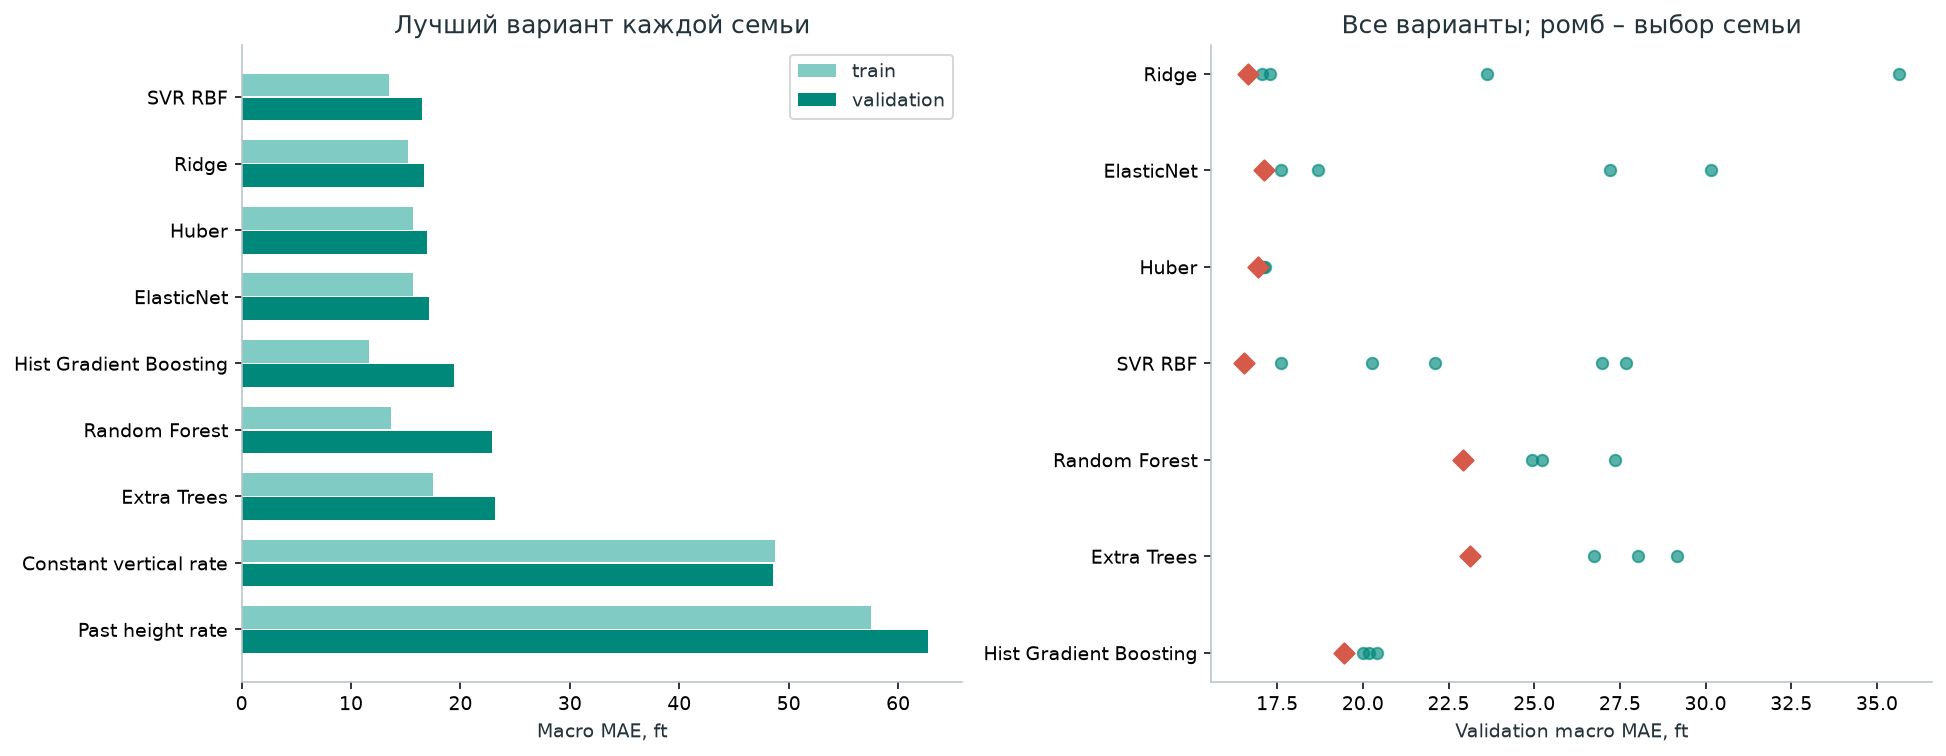

In [5]:
# Сопоставляем train и validation до просмотра новых прогнозов test
train_metrics = pd.DataFrame([summarize(train, forecast(model, train, FEATURES), name)
    for name, model in all_models.items()])
train_metrics.to_csv(REPORTS / '05_train_metrics.csv', index=False)
order = validation_metrics.model.tolist()
train_values = train_metrics.set_index('model').loc[order, 'macro_mae_ft']
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
y = np.arange(len(order))
axes[0].barh(y - .18, train_values, height=.34, color='#80CBC4', label='train')
axes[0].barh(y + .18, validation_metrics.macro_mae_ft, height=.34, color=GREEN, label='validation')
axes[0].set(yticks=y, yticklabels=order, xlabel='Macro MAE, ft',
            title='Лучший вариант каждой семьи')
axes[0].invert_yaxis()
axes[0].legend()
families = family_table.model.tolist()
for i, name in enumerate(families):
    values = tuning.loc[tuning.model.eq(name)]
    axes[1].scatter(values.macro_mae_ft, np.full(len(values), i),
                    color=GREEN, s=35, alpha=.65)
    best = validation_metrics.loc[validation_metrics.model.eq(name), 'macro_mae_ft'].iloc[0]
    axes[1].scatter(best, i, marker='D', color=RED, s=55)
axes[1].set(yticks=np.arange(len(families)), yticklabels=families,
            xlabel='Validation macro MAE, ft', title='Все варианты; ромб – выбор семьи')
axes[1].invert_yaxis()
fig.tight_layout()
savefig(fig, '05_validation_comparison')

## 05 Реакция прогноза на текущую Vz

Проверяем локальную реакцию полной формулы прогноза при изменении только текущей барометрической Vz на ±1 ft/s. Остальные признаки оставляем неизменными. Это диагностика модели в исходных точках validation, а не физически согласованная имитация аномального захода.

$$S_{Vz}=\frac{\widehat h(V_z+\delta)-\widehat h(V_z-\delta)}{2\delta\tau}.$$

У продолжения текущей Vz отношение равно 1. Значение около 0 означает, что поправка почти подавляет ее прямое влияние. У прогноза по прошлой высотной динамике это влияние равно 0 по определению. Малое значение само по себе не доказывает, что модель пропустит уход, но объясняет, почему одной MAE недостаточно для выбора будущего индикатора риска.

model,median_vz_response_ratio,p10_vz_response_ratio,p90_vz_response_ratio
Constant vertical rate,1.00,1.00,1.00
Past height rate,0.00,0.00,0.00
Ridge,0.03,-0.06,0.09
ElasticNet,0.05,-0.04,0.10
Huber,0.04,-0.04,0.10
SVR RBF,0.09,-0.04,0.32
Random Forest,0.22,-0.25,0.54
Extra Trees,0.27,0.11,0.46
Hist Gradient Boosting,0.06,-0.22,0.35


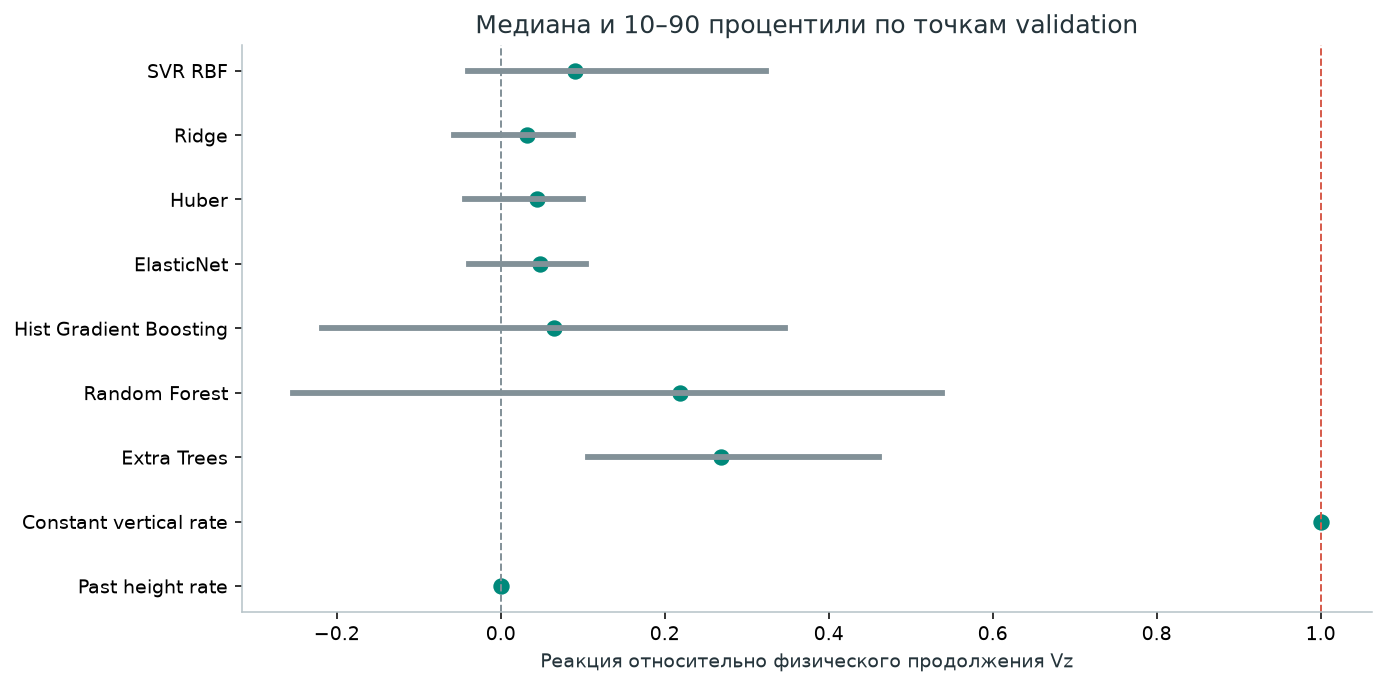

In [6]:
# Используем validation для диагностического изменения текущей Vz
response = pd.DataFrame([{'model': name, **current_rate_response(model, validation, FEATURES,
    plan['sensitivity_delta_vertical_rate_fps'])} for name, model in all_models.items()])
response.to_csv(REPORTS / '05_vz_response.csv', index=False)
table(response)
view = response.set_index('model').loc[order].reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
for i, row in view.iterrows():
    ax.plot([row.p10_vz_response_ratio, row.p90_vz_response_ratio], [i, i], color=GREY, lw=3)
    ax.scatter(row.median_vz_response_ratio, i, c=GREEN, s=55)
ax.axvline(0, color=GREY, ls='--', lw=1)
ax.axvline(1, color=RED, ls='--', lw=1)
ax.set(yticks=np.arange(len(view)), yticklabels=view.model,
       xlabel='Реакция относительно физического продолжения Vz',
       title='Медиана и 10–90 процентили по точкам validation')
ax.invert_yaxis()
fig.tight_layout()
savefig(fig, '05_vz_response')

## 06 Повторное сравнение на test

Параметры всех семейств и выбранный прогноз уже записаны. Теперь вычисляем результаты на прежних восьми test-заходах, принадлежащих семи ICAO24. Модели не переобучаются.

Основная метрика – среднее MAE заходов с равным весом каждого. Macro RMSE, построчный 95-й процентиль абсолютной ошибки и смещение показывают другие стороны результата. Положительная ошибка означает завышение прогнозируемой высоты. Рейтинг test является описательным; выбор модели сохраняется по validation.

model,selected_on_validation,macro_mae_ft,macro_rmse_ft,point_p95_abs_ft,macro_bias_ft,improvement_vs_current_vz_pct
Ridge,False,23.71,31.95,61.71,-5.43,65.01
ElasticNet,False,24.75,34.23,69.61,-7.82,63.46
Huber,False,24.82,34.34,68.48,-7.82,63.36
SVR RBF,True,27.07,41.91,80.31,-8.38,60.04
Hist Gradient Boosting,False,32.45,53.04,113.72,-11.81,52.09
Random Forest,False,35.98,55.66,102.74,-8.03,46.88
Extra Trees,False,36.19,56.43,111.78,-7.82,46.58
Constant vertical rate,False,67.75,96.17,182.38,-28.86,0.00
Past height rate,False,74.44,106.03,209.52,-24.68,-9.88


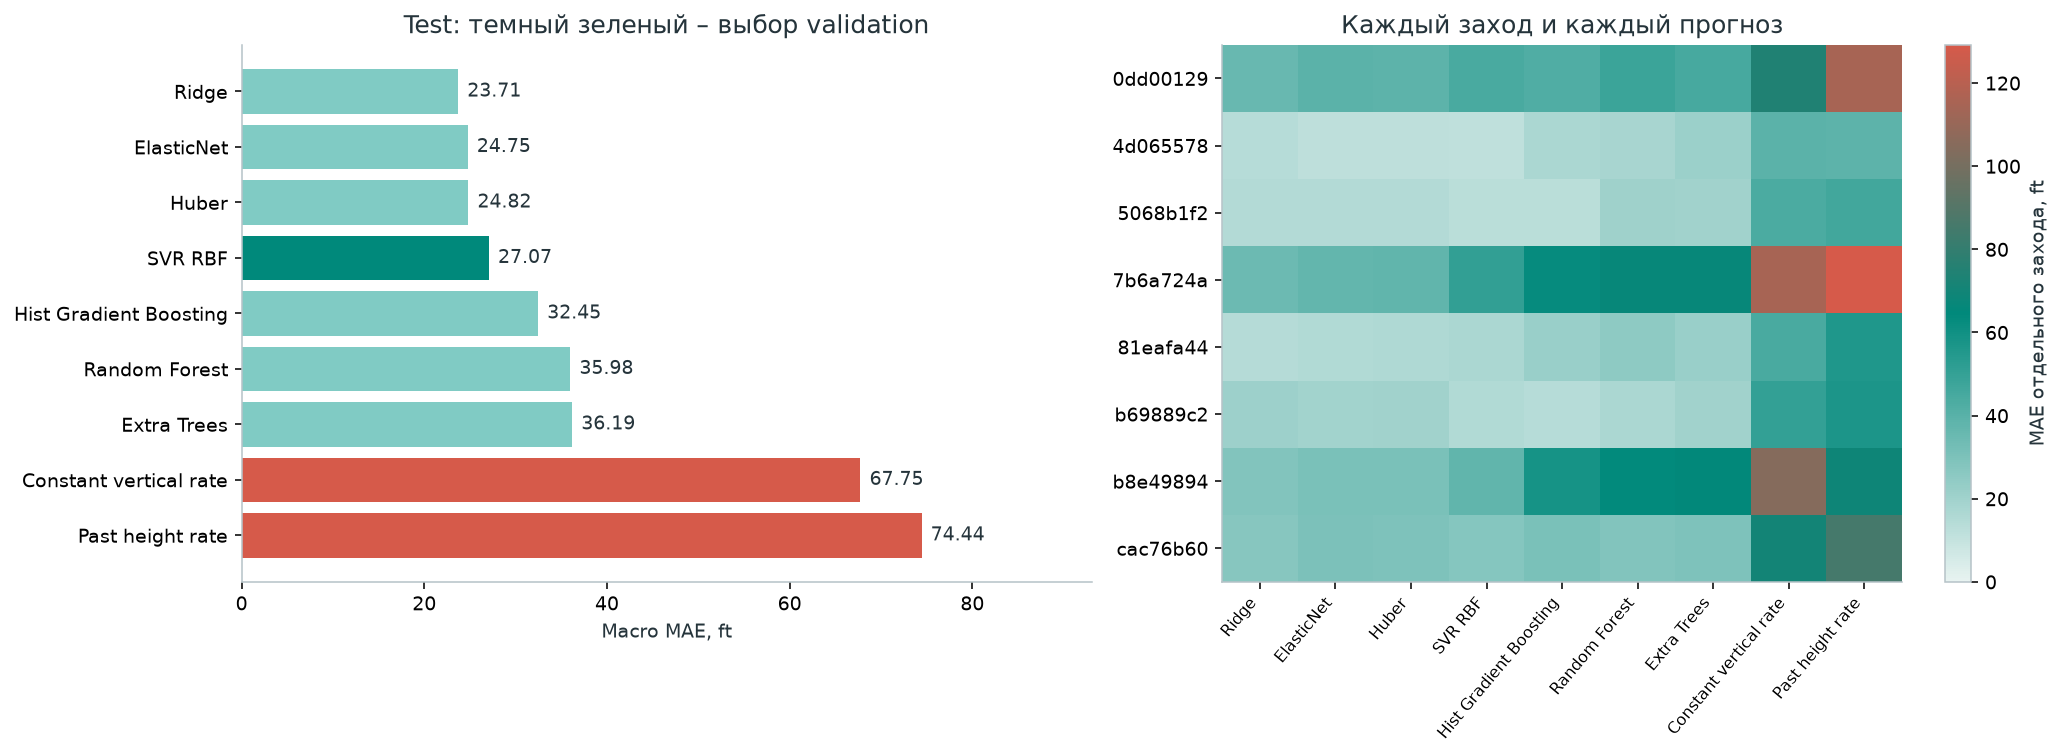

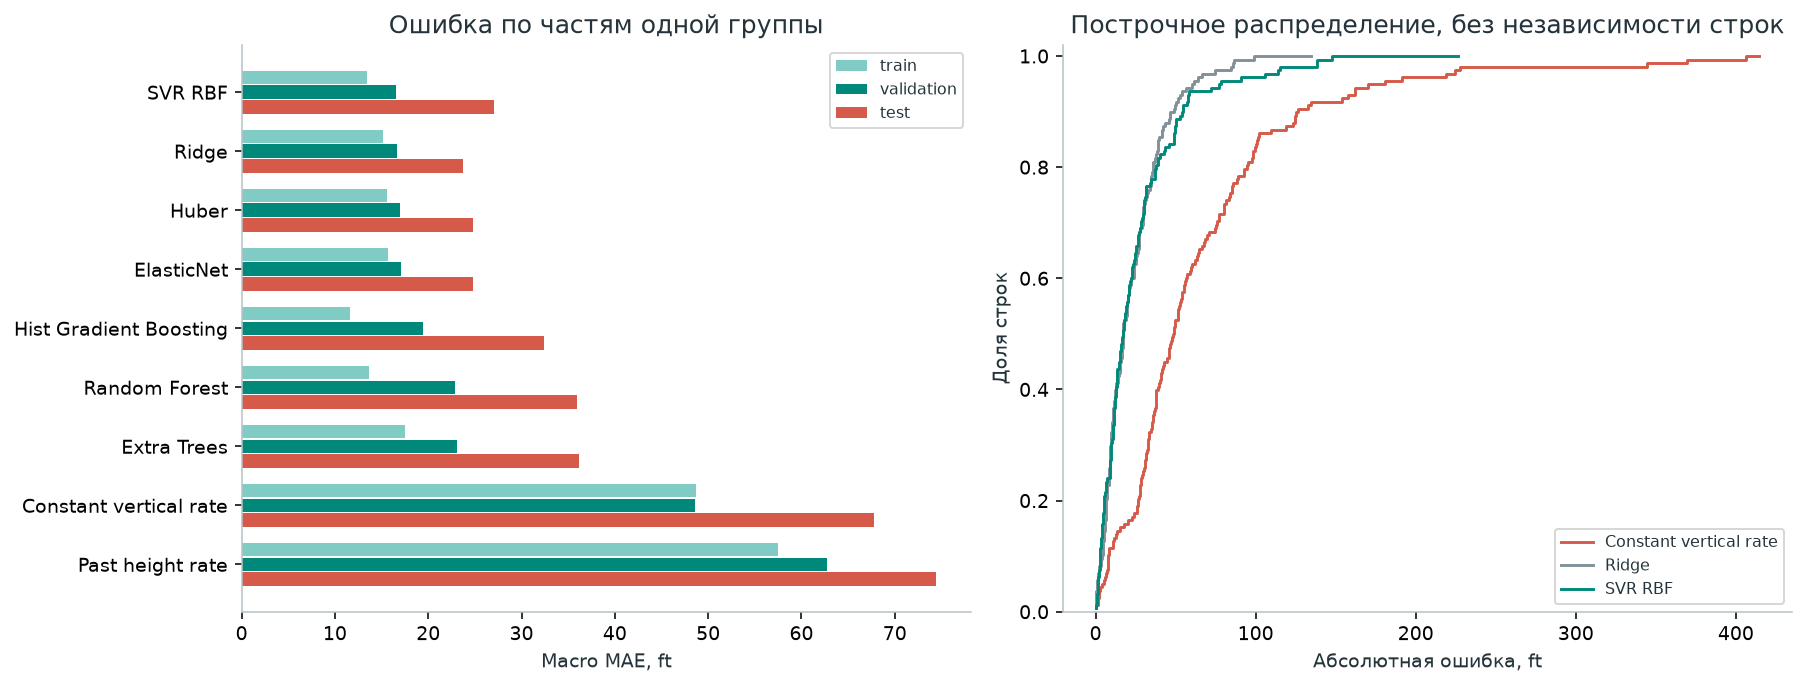

In [7]:
# Повторно оцениваем общую test-группу после сохранения выбора
assert (REPORTS / '05_model_selection.json').exists()
test = examples.loc[examples.split.eq('test')].copy()
assert test.event_id.nunique() == 8 and test.icao24.nunique() == 7
test_forecasts = {name: forecast(model, test, FEATURES) for name, model in all_models.items()}
test_metrics = pd.DataFrame([summarize(test, test_forecasts[name], name) for name in all_models])
test_metrics = test_metrics.sort_values(['macro_mae_ft', 'model']).reset_index(drop=True)
test_metrics['selected_on_validation'] = test_metrics.model.eq(winner)
baseline_mae = float(test_metrics.loc[test_metrics.model.eq('Constant vertical rate'), 'macro_mae_ft'].iloc[0])
test_metrics['improvement_vs_current_vz_pct'] = 100 * (1 - test_metrics.macro_mae_ft / baseline_mae)
test_metrics.to_csv(REPORTS / '05_test_metrics.csv', index=False)
per_event = pd.concat([event_errors(test, test_forecasts[name], name)
    for name in all_models], ignore_index=True)
per_event.to_csv(REPORTS / '05_test_event_metrics.csv', index=False)
prediction_rows = pd.concat([test.assign(model=name, prediction_ft=test_forecasts[name])
    for name in all_models], ignore_index=True)
prediction_rows.to_parquet(BASE / 'data/2025-01-15/training_05_predictions.parquet', index=False)

# Ridge этапа 05 обязана воспроизвести уже опубликованную модель этапа 04
old_ridge = joblib.load(BASE / 'artifacts/training_04/altitude_residual_ridge.joblib')
assert np.allclose(test_forecasts['Ridge'],
    test.baseline_ft + old_ridge['model'].predict(test[FEATURES]))
table(test_metrics[['model', 'selected_on_validation', 'macro_mae_ft', 'macro_rmse_ft',
                    'point_p95_abs_ft', 'macro_bias_ft', 'improvement_vs_current_vz_pct']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
test_order = test_metrics.model.tolist()
bars = axes[0].barh(test_order, test_metrics.macro_mae_ft,
    color=[GREEN if name == winner else '#80CBC4' if name in selected_models else RED
           for name in test_order])
for bar, value in zip(bars, test_metrics.macro_mae_ft):
    axes[0].text(value + 1, bar.get_y() + bar.get_height()/2, f'{value:.2f}', va='center')
axes[0].set(xlabel='Macro MAE, ft', title='Test: темный зеленый – выбор validation',
            xlim=(0, test_metrics.macro_mae_ft.max()*1.25))
axes[0].invert_yaxis()
matrix = per_event.pivot(index='event_id', columns='model', values='mae_ft')[test_order]
error_colors = LinearSegmentedColormap.from_list('approach_errors', ['#E8F3F1', GREEN, RED])
image = axes[1].imshow(matrix.to_numpy(), aspect='auto', cmap=error_colors, vmin=0)
axes[1].set(xticks=np.arange(len(test_order)), xticklabels=test_order,
    yticks=np.arange(len(matrix)), yticklabels=[name[:8] for name in matrix.index],
    title='Каждый заход и каждый прогноз')
plt.setp(axes[1].get_xticklabels(), rotation=50, ha='right', fontsize=8)
fig.colorbar(image, ax=axes[1], label='MAE отдельного захода, ft')
fig.tight_layout()
savefig(fig, '05_test_comparison')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
comparison = pd.concat([train_metrics.assign(split='train'),
    validation_metrics.assign(split='validation'), test_metrics.assign(split='test')], ignore_index=True)
comparison.to_csv(REPORTS / '05_split_metrics.csv', index=False)
for shift, split, color in [(-.25, 'train', '#80CBC4'), (0, 'validation', GREEN), (.25, 'test', RED)]:
    values = comparison.loc[comparison.split.eq(split)].set_index('model').loc[order, 'macro_mae_ft']
    axes[0].barh(np.arange(len(order)) + shift, values, height=.23, color=color, label=split)
axes[0].set(yticks=np.arange(len(order)), yticklabels=order,
            xlabel='Macro MAE, ft', title='Ошибка по частям одной группы')
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
for name, color in [('Constant vertical rate', RED), ('Ridge', GREY), (winner, GREEN)]:
    if name == winner and name in {'Constant vertical rate', 'Ridge'}:
        continue
    absolute = np.sort(np.abs(test_forecasts[name] - test.target_height_ft.to_numpy()))
    axes[1].step(absolute, np.arange(1, len(absolute)+1)/len(absolute), label=name, color=color)
axes[1].set(xlabel='Абсолютная ошибка, ft', ylabel='Доля строк',
            title='Построчное распределение, без независимости строк', ylim=(0, 1.02))
axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, '05_generalization_and_errors')

## 07 Парное сравнение целыми бортами

В каждой bootstrap-выборке повторно выбираются ICAO24; все заходы одного выбранного борта остаются вместе. Для каждой модели сравниваем MAE с текущей Vz и отдельно с Ridge. Отрицательная разность означает меньшую ошибку.

Интервалы условны для фиксированных моделей и этой группы. Они не учитывают поиск по семействам, множественные сравнения, неопределенность выбора на validation или изменчивость других дней. Это диагностические интервалы, а не основание объявить модель универсально лучшей.

model,delta_macro_mae_ft,interval_2_5_ft,interval_97_5_ft,independent_aircraft
SVR RBF,3.37,-1.32,8.16,7
Ridge,0.00,0.00,0.00,7
Huber,1.11,-0.42,2.27,7
ElasticNet,1.05,-0.51,2.28,7
Hist Gradient Boosting,8.75,0.23,16.31,7
Random Forest,12.28,4.26,19.84,7
Extra Trees,12.48,4.89,19.78,7
Constant vertical rate,44.04,29.46,57.78,7
Past height rate,50.73,36.11,67.98,7


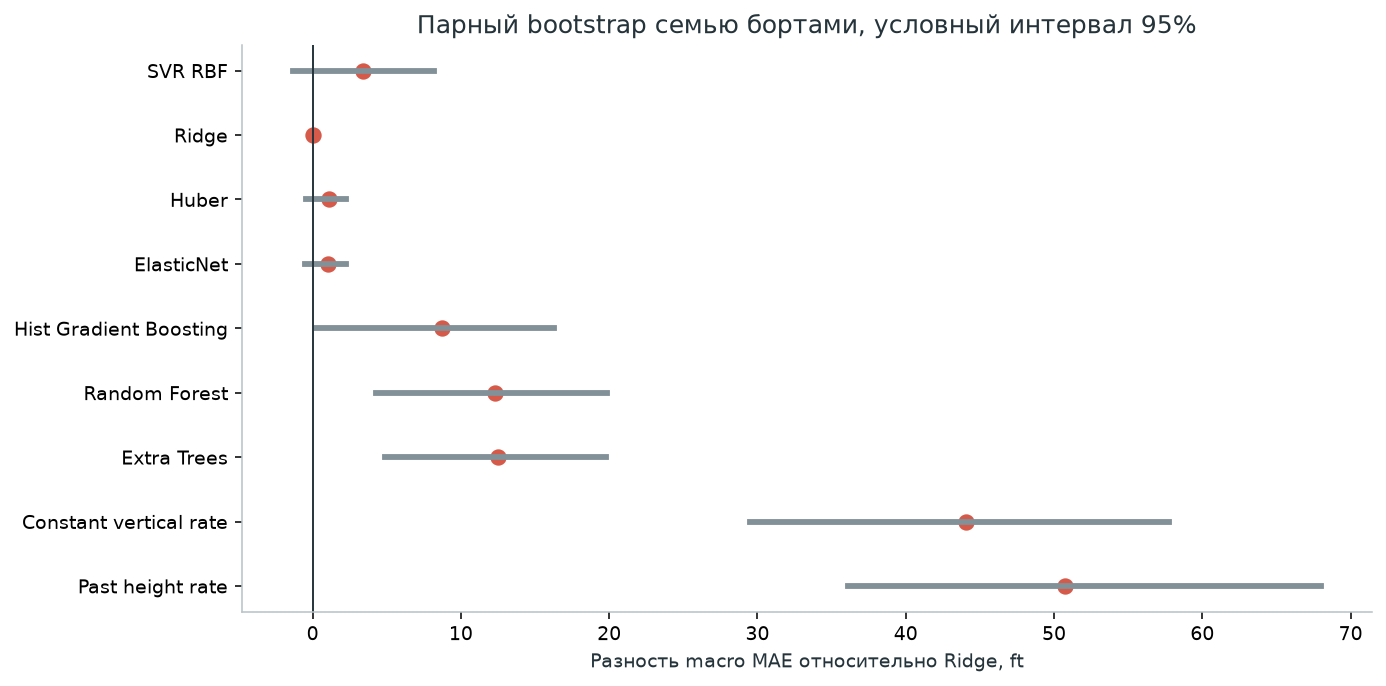

In [8]:
# Сохраняем обе точки сравнения с одинаковыми единицами повторного выбора
intervals = pd.concat([paired_intervals(per_event, reference, plan['seed'] + 5,
    plan['bootstrap_repetitions']) for reference in ['Constant vertical rate', 'Ridge']],
    ignore_index=True)
intervals.to_csv(REPORTS / '05_paired_intervals.csv', index=False)
ridge_intervals = intervals.loc[intervals.reference.eq('Ridge')].set_index('model').loc[order].reset_index()
table(ridge_intervals[['model', 'delta_macro_mae_ft', 'interval_2_5_ft',
                       'interval_97_5_ft', 'independent_aircraft']])
fig, ax = plt.subplots(figsize=(10, 5))
for i, row in ridge_intervals.iterrows():
    ax.plot([row.interval_2_5_ft, row.interval_97_5_ft], [i, i], color=GREY, lw=3)
    ax.scatter(row.delta_macro_mae_ft, i,
               color=GREEN if row.delta_macro_mae_ft < 0 else RED, s=55)
ax.axvline(0, color=INK, lw=1)
ax.set(yticks=np.arange(len(order)), yticklabels=order,
       xlabel='Разность macro MAE относительно Ridge, ft',
       title='Парный bootstrap семью бортами, условный интервал 95%')
ax.invert_yaxis()
fig.tight_layout()
savefig(fig, '05_paired_vs_ridge')

## 08 Как ведут себя отдельные заходы

Для иллюстрации выбираем три захода по ошибке исходного физического baseline: максимальную, среднюю по рангу и минимальную. Так выбор примеров не зависит от того, на каком заходе новая модель выглядит удачнее.

По оси времени показано время целевой точки, по вертикали – будущий высотный прокси. Черные точки – наблюдаемые цели на QNH момента соответствующего прогноза. Каждая цветная точка – прогноз, сделанный за 27–33 с до цели. Линии только соединяют последовательные значения.

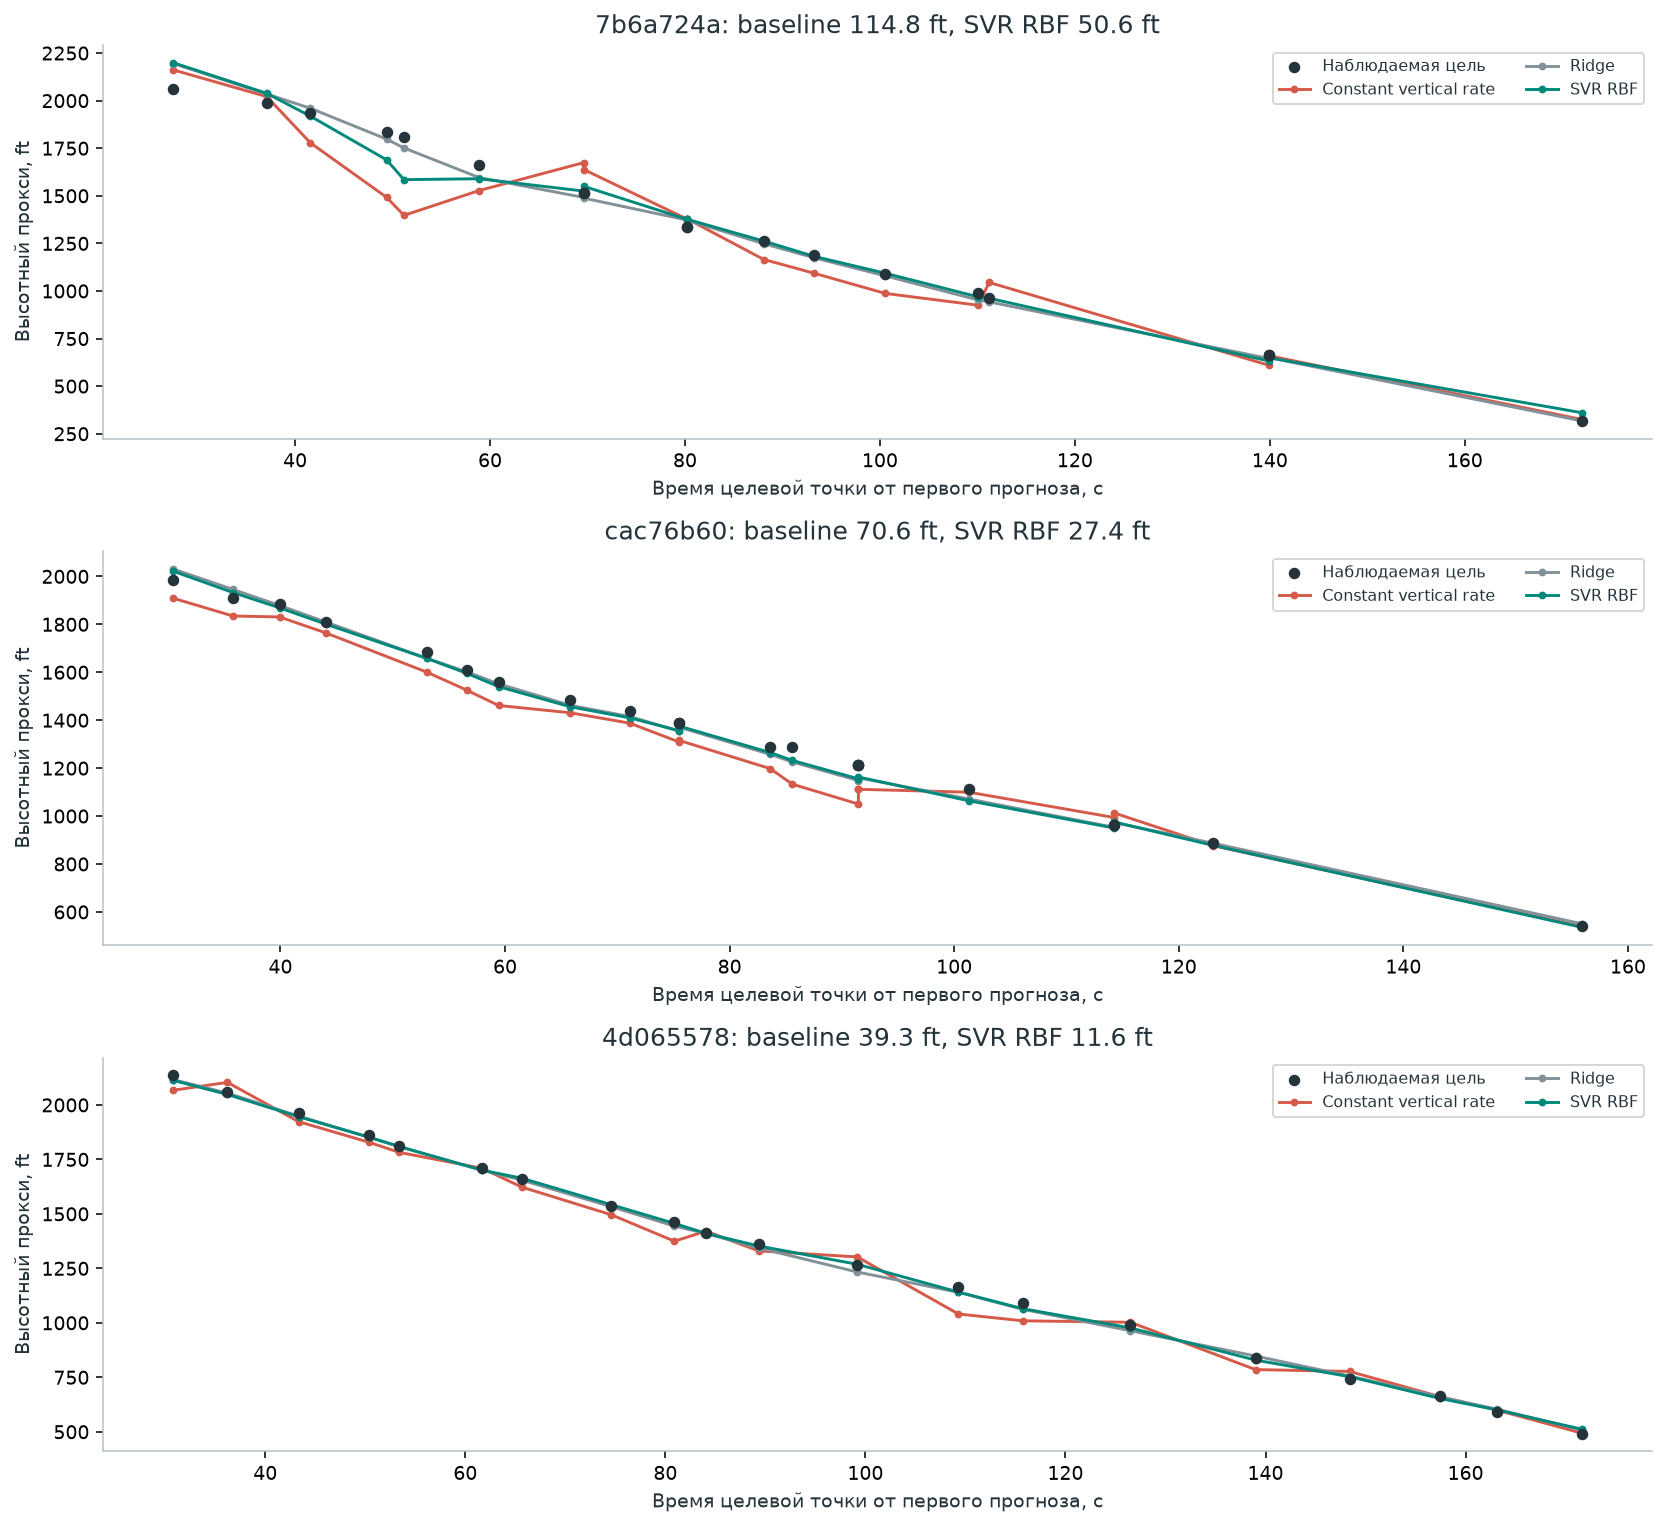

In [9]:
# Фиксируем правило выбора примеров по физическому baseline
baseline_events = per_event.loc[per_event.model.eq('Constant vertical rate')].sort_values('mae_ft')
case_ids = baseline_events.iloc[[len(baseline_events)-1, len(baseline_events)//2, 0]].event_id.tolist()
case_rows = []
fig, axes = plt.subplots(3, 1, figsize=(12, 11))
shown = list(dict.fromkeys(['Constant vertical rate', 'Ridge', winner]))
colors = {'Constant vertical rate': RED, 'Ridge': GREY, winner: GREEN}
for ax, event_id in zip(axes, case_ids):
    mask = test.event_id.eq(event_id).to_numpy()
    group = test.loc[mask]
    x = (group.target_time - group.origin_time.min()).to_numpy()
    ax.scatter(x, group.target_height_ft, c=INK, s=24, label='Наблюдаемая цель', zorder=4)
    for name in shown:
        ax.plot(x, test_forecasts[name][mask], '.-', c=colors[name], label=name, lw=1.5)
    event_values = per_event.loc[per_event.event_id.eq(event_id)].set_index('model')
    ax.set(title=f"{event_id[:8]}: baseline {event_values.loc['Constant vertical rate', 'mae_ft']:.1f} ft, "
                 f"{winner} {event_values.loc[winner, 'mae_ft']:.1f} ft",
           xlabel='Время целевой точки от первого прогноза, с', ylabel='Высотный прокси, ft')
    ax.legend(fontsize=8, ncol=2)
    case_rows.append({'event_id': event_id,
        'baseline_mae_ft': float(event_values.loc['Constant vertical rate', 'mae_ft']),
        'selected_mae_ft': float(event_values.loc[winner, 'mae_ft']), 'selected_model': winner})
fig.tight_layout()
savefig(fig, '05_approach_cases')
pd.DataFrame(case_rows).to_csv(REPORTS / '05_case_selection.csv', index=False)

## 09 Результат и авиационная интерпретация

Выбор по validation и описательный лидер test могут различаться. Ниже они названы отдельно. Снижение высотной ошибки не превращается в оценку риска или вероятность ухода на второй круг.

Геометрическая привязка 09L остается предварительной; захват ILS, истинная высота и исход захода не подтверждены. Исторический комплект NOTAM на 15.01.2025 не получен. [A3237/26](../reports/04_NOTAM_09L_A3237-26.md) относится к другому периоду и не входит в признаки.

Группа отобрана по наблюдаемому покрытию до прокси 300 ft; ранние уходы и неполные траектории могут в нее не попасть. Модель, успешно описывающая обычное снижение, требует отдельной проверки реакции на нестабильные профили. Локальная чувствительность к Vz помогает сформулировать такую проверку, но не заменяет ее.

In [10]:
# Формируем вывод из реально выполненных расчетов
selected_test = test_metrics.loc[test_metrics.model.eq(winner)].iloc[0]
ridge_test = test_metrics.loc[test_metrics.model.eq('Ridge')].iloc[0]
descriptive_test_leader = str(test_metrics.iloc[0].model)
chosen_interval = intervals.loc[intervals.reference.eq('Ridge') & intervals.model.eq(winner)].iloc[0]
panel('Результат сравнения',
    f'Выбор validation: {winner}. Test macro MAE: {selected_test.macro_mae_ft:.2f} ft.<br>'
    f'Текущая Vz: {baseline_mae:.2f} ft; Ridge: {ridge_test.macro_mae_ft:.2f} ft.<br>'
    f'Описательный лидер test: {descriptive_test_leader}; выбор по нему не меняется.<br>'
    f'Разность выбранной модели и Ridge: {chosen_interval.delta_macro_mae_ft:+.2f} ft; '
    f'условный интервал [{chosen_interval.interval_2_5_ft:+.2f}; {chosen_interval.interval_97_5_ft:+.2f}] ft')

manifest = {'study': plan['study'], 'data_date': plan['data_date'],
    'candidate_events': len(cohort), 'aircraft': int(cohort.icao24.nunique()), 'observed_pairs': len(examples),
    'split': split_summary.reset_index().to_dict(orient='records'),
    'tested_parameter_variants': len(tuning), 'trained_families': len(selected_models),
    'winner_by_validation': winner, 'best_ml_by_validation': best_ml,
    'descriptive_test_leader': descriptive_test_leader,
    'baseline_macro_mae_ft': baseline_mae, 'ridge_macro_mae_ft': float(ridge_test.macro_mae_ft),
    'selected_test_macro_mae_ft': float(selected_test.macro_mae_ft),
    'test_previously_inspected': True, 'independent_new_test': False,
    'selection_uses_test_scores': False, 'refit_on_validation': False,
    'future_weather_used': False, 'target_interpolation': False, 'feature_selection': False,
    'goaround_model_trained': False, 'historical_notam_verified': False,
    'input_sha256': {'examples': digest(examples_path), 'cohort': digest(cohort_path),
        'prior_manifest': digest(REPORTS / '04_training_manifest.json'), 'plan': digest(plan_path)},
    'selection_sha256': digest(REPORTS / '05_model_selection.json'),
    'model_sha256': digest(ARTIFACTS / 'selected_models.joblib'),
    'predictions_sha256': digest(BASE / 'data/2025-01-15/training_05_predictions.parquet'),
    'implementation_sha256': {str(path.relative_to(PROJECT)).replace(chr(92), '/'): digest(path)
        for path in [PROJECT / 'scripts/lfpg_model_comparison.py',
                     PROJECT / 'scripts/build_lfpg_model_comparison_notebook.py',
                     PROJECT / 'scripts/execute_notebook.py']},
    'environment': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                    'numpy': np.__version__, 'pandas': pd.__version__}}
(REPORTS / '05_comparison_manifest.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
report = ['# LFPG 09L – сравнение моделей прогноза высотной динамики', '',
    '37 кандидатов, 35 бортов, 633 пары наблюдений за 15.01.2025. '
    'Разделение этапа 04 сохранено: 21 train, 8 validation, 8 test; test содержит 7 бортов.', '',
    f'Обучение выполнено для {len(tuning)} вариантов в {len(selected_models)} семействах. '
    'Признаки, target, физический baseline и веса заходов одинаковы. '
    'Параметры и выбранный прогноз определены по validation macro MAE.', '',
    f'Выбор validation: **{winner}**, test macro MAE **{selected_test.macro_mae_ft:.2f} ft**. '
    f'Описательный лидер test: **{descriptive_test_leader}**; выбор по нему не меняется.', '',
    '| Прогноз | Validation MAE, ft | Test MAE, ft | Test RMSE, ft |',
    '|---|---:|---:|---:|']
for name in order:
    val = validation_metrics.loc[validation_metrics.model.eq(name)].iloc[0]
    result = test_metrics.loc[test_metrics.model.eq(name)].iloc[0]
    report.append(f'| {name} | {val.macro_mae_ft:.2f} | {result.macro_mae_ft:.2f} | {result.macro_rmse_ft:.2f} |')
report.extend(['', f'Выбранная модель минус Ridge: {chosen_interval.delta_macro_mae_ft:+.2f} ft; '
    f'условный парный интервал [{chosen_interval.interval_2_5_ft:+.2f}; '
    f'{chosen_interval.interval_97_5_ft:+.2f}] ft. Bootstrap целыми бортами.', '',
    'Результаты этих test-заходов уже просмотрены в этапе 04. Это исследовательское '
    'сравнение на повторно используемой группе; интервал не учитывает выбор модели и '
    'множественные сравнения. Подтверждение требует другого дня.', '',
    'Высотная точность не измеряет способность обнаружить нестабильность или GoA. '
    'Реакция на текущую Vz проверена отдельно на validation путем изолированного изменения признака. '
    'Это диагностика формулы, не имитация физически согласованного полета.', '',
    'Захват ILS, истинная высота, исходы GoA и исторические NOTAM не подтверждены. '
    'Контрольные 300 ft являются исследовательским барометрическим прокси.', '',
    '[Выполненный ноутбук](../notebooks/05_model_comparison.ipynb), '
    '[фиксированный протокол](05_comparison_protocol.json), '
    '[выбор по validation](05_model_selection.json), '
    '[манифест](05_comparison_manifest.json).', ''])
(REPORTS / '05_model_comparison_result.md').write_text(chr(10).join(report), encoding='utf-8')
print('Модели, прогнозы, таблицы, рисунки и контрольные суммы сохранены')

Модели, прогнозы, таблицы, рисунки и контрольные суммы сохранены


## 10 Следующий проверяемый шаг

Сохранить выбранную на validation модель и компактную сетку без расширения по test. Проверить зафиксированный прогноз на другом дне LFPG 09L с теми же причинными правилами и отдельно рассмотреть профили с изменением вертикальной динамики. Только затем обсуждать переносимость на EGLL или индикатор риска.

**Воспроизведение:** из корня проекта `python scripts/build_lfpg_model_comparison_notebook.py`. Проверка сериализованных моделей, прогнозов, выбора и сохраненных выводов: `python scripts/verify_lfpg_model_comparison.py`.

Данные и модели находятся в игнорируемых `data` и `artifacts`; таблицы и рисунки – в `reports/05_*` и `figures/05_*`. Этап 04 сохраняется как исходный эксперимент.

**Происхождение:** [ADSB.lol, архив 2025](https://github.com/adsblol/globe_history_2025), [формат trace readsb](https://github.com/wiedehopf/readsb/blob/dev/README-json.md), [OurAirports](https://ourairports.com/data/), [IEM METAR](https://mesonet.agron.iastate.edu/request/download.phtml?network=FR__ASOS). Сырые данные ADSB.lol опубликованы под ODbL 1.0; этот этап наследует их происхождение и контрольные суммы из этапов 02–04.